# Classical vs Diffusion-Based Inpainting for Photo Restoration — Pilot Study (Results notebook)

This notebook runs the full comparison described in the paper. Given **20 undamaged photographs from an open photograph collection**, it first adds three irregular masks to each photograph (about 5 %, 20 % and 40 % of the image). The PDE-based, exemplar-based and diffusion-based methods then each restore every damaged image with their default settings, giving **180 restored outputs**. The two classical methods serve as the **baseline** for the diffusion-based method. Quality is measured against the original photograph with PSNR, SSIM and LPIPS, and processing time is recorded for every image. Visible artefacts and invented details are shown side by side in the qualitative comparison figures.

| Design element | Implementation in this notebook |
|---|---|
| Photographs | 20 undamaged photos from the open **Berkeley Segmentation Dataset BSDS500** (test split; Arbeláez et al., IEEE TPAMI 2011): 7 portraits, 7 landscapes, 6 group photos — downloaded automatically and checksum-verified |
| Independent variable 1: method (3 levels) | PDE-based (OpenCV Navier–Stokes), exemplar-based (Criminisi), diffusion-based (ResShift [17], pretrained, 4 sampling steps) — all with default settings; the two classical methods are the **baseline** |
| Independent variable 2: damage severity (3 levels) | Irregular stroke + blotch masks covering ≈5 %, 20 %, 40 % of the image |
| Dependent variables | PSNR, SSIM, LPIPS, processing time (s) |
| Blocking factor | Image content: `portrait`, `landscape`, `group` |
| Control | Same photographs and same masks for all three methods; common resolution 256×256; default settings; randomised run order |
| Sample | 20 images × 3 levels × 3 methods = **180 restored outputs** |

**How to use**
1. `Runtime → Change runtime type → GPU` (T4 is enough).
2. Nothing to prepare: the 20 photographs are downloaded automatically.
3. `Runtime → Run all` (about 15–20 minutes on a T4).
4. Everything (tables, figures, CSVs, LaTeX) is saved to `OUT_DIR` and downloaded as one zip at the end (Section 14). Set `USE_DRIVE = True` in Cell 2 if you also want a copy in your Google Drive.

## 1. Setup — GPU check, packages, ResShift model code

In [ ]:
import subprocess, sys, os
gpu = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                     capture_output=True, text=True).stdout.strip()
print('GPU:', gpu if gpu else 'NONE — switch the runtime to GPU before continuing!')

!pip -q install omegaconf loguru loralib lpips einops timm scikit-image albumentations
if not os.path.exists('/content/ResShift'):
    !git clone -q https://github.com/zsyOAOA/ResShift.git /content/ResShift
print('Setup done.')

GPU: Tesla T4, 15360 MiB
Setup done.


## 2. Configuration — edit these paths

In [ ]:
from pathlib import Path

DATA_SOURCE = 'BSDS500'     # 'BSDS500' = the 20 fixed open-collection photos (as in the paper) | 'folder' = your own photos in CLEAN_DIR

USE_DRIVE = False           # True = save results to Google Drive (survives Colab restarts)
CLEAN_DIR = '/content/drive/MyDrive/inpainting_study/clean'        # only used when DATA_SOURCE = 'folder' (names: portrait_*, landscape_*, group_*)
OUT_DIR   = '/content/results'                                     # replaced by a Drive folder when USE_DRIVE = True

IMG_SIZE    = 256                                   # common resolution (ResShift was trained at 256×256)
LEVELS      = {'small': 0.05, 'medium': 0.20, 'large': 0.40}
MASK_TOL    = 0.01                                  # accepted coverage error (±1 percentage point)
SEED        = 2026
CATEGORIES  = ['portrait', 'landscape', 'group']

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:
        USE_DRIVE = False; print('Not running in Colab — writing to', OUT_DIR)
    except Exception as e:                       # e.g. "credential propagation was unsuccessful"
        USE_DRIVE = False
        print('⚠ Google Drive could not be mounted:', e)
        print('  Fix: run this cell again and, in the pop-up, choose your account and tick ALL permission boxes')
        print('       (allow pop-ups for colab.research.google.com; use the same Google account as Colab).')
        print('  Or:  Files panel (folder icon, left) → "Mount Drive" button, then run this cell again.')
        print('  For now results go to', OUT_DIR, '— this folder is DELETED when the Colab session ends,')
        print('  so download the zip at the end (Section 14).')
if USE_DRIVE:
    OUT_DIR = '/content/drive/MyDrive/inpainting_study/results'   # survives Colab restarts

OUT = Path(OUT_DIR)
for sub in ['clean', 'masks', 'damaged', 'restored', 'figures', 'tables']:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
print('Outputs will be written to', OUT.resolve())

Outputs will be written to /content/results


## 3. Imports and environment record (report these versions in Section III-B)

In [ ]:
import os, sys, random, time, json, math, platform, glob, shutil
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import skimage, scipy
from scipy import stats

def set_all_seeds(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_all_seeds(SEED)

env = {
    'python': platform.python_version(), 'torch': torch.__version__, 'opencv': cv2.__version__,
    'scikit-image': skimage.__version__, 'numpy': np.__version__,
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none',
    'gpu_memory_GB': round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1) if torch.cuda.is_available() else 0,
    'cpu': platform.processor() or platform.machine(), 'cpu_threads': os.cpu_count(),
}
json.dump(env, open(OUT / 'tables' / 'environment.json', 'w'), indent=2)

# ---------- Figure theme: one look for every figure in the notebook ----------
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

INK, INK2, MUTED = '#0b0b0b', '#52514e', '#898781'            # text: primary / secondary / muted
GRID, AXIS, SURFACE = '#e1e0d9', '#c3c2b7', '#ffffff'           # hairline grid, axis line, background
COL = {'PDE': '#2a78d6', 'Exemplar': '#eb6834', 'Diffusion': '#1baf7a'}   # colour-blind-safe (validated) categorical slots 1-3
MRK = {'PDE': 'o', 'Exemplar': 's', 'Diffusion': '^'}                      # marker = second channel, colour is never alone
HW  = {'PDE': 'CPU', 'Exemplar': 'CPU', 'Diffusion': 'GPU'}
DAMAGE_EDGE = '#e34948'                                                    # outline of damaged areas in image figures

mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 8, 'axes.titlesize': 8.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlecolor': INK, 'axes.titlepad': 6, 'axes.labelsize': 7.5, 'axes.labelcolor': INK2,
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'xtick.color': AXIS, 'ytick.color': AXIS, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'xtick.major.size': 0, 'ytick.major.size': 0,
    'xtick.minor.size': 0, 'ytick.minor.size': 0, 'xtick.major.pad': 4, 'ytick.major.pad': 4,
    'legend.frameon': False, 'legend.fontsize': 7.5, 'legend.handlelength': 1.8, 'legend.columnspacing': 1.6,
    'lines.linewidth': 1.6, 'lines.markersize': 5, 'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'savefig.facecolor': SURFACE, 'figure.dpi': 130, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.04, 'pdf.fonttype': 42, 'ps.fonttype': 42,
})

def chart_ax(ax, grid='y'):
    # recessive chart chrome: hairline grid on the value axis, no tick marks
    if grid: ax.grid(True, axis=grid)
    ax.tick_params(length=0)

def panel_title(ax, letter, title, note=None):
    # "(a) PSNR (dB)" in bold + a muted note such as "higher is better"
    ax.set_title(f'({letter})  {title}' if letter else title, loc='left')
    if note: ax.annotate(note, xy=(1.0, 1.0), xycoords='axes fraction', xytext=(0, mpl.rcParams['axes.titlepad']),
                         textcoords='offset points', ha='right', va='baseline', fontsize=6.5, color=MUTED)

def image_ax(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)

def method_handles(with_hw=False):
    return [Line2D([], [], color=COL[m], marker=MRK[m], lw=1.6, ms=5.5, mec='white', mew=0.8,
                   label=f'{m} ({HW[m]})' if with_hw else m) for m in METHODS_ORDER]

def top_legend(fig, handles, y=1.0, ncol=None):
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, y), ncol=ncol or len(handles),
               handletextpad=0.5)

def show_damage(ax, img, mask):
    # damaged pixels shown white (what the methods receive) with a thin red outline so small scratches stay visible
    d = img.copy(); d[mask.astype(bool)] = 255
    ax.imshow(d); ax.contour(mask.astype(float), levels=[0.5], colors=[DAMAGE_EDGE], linewidths=0.35)

def save_fig(fig, name, pdf=True):
    fig.savefig(OUT / 'figures' / f'{name}.png')
    if pdf: fig.savefig(OUT / 'figures' / f'{name}.pdf')

METHODS_ORDER = ['PDE', 'Exemplar', 'Diffusion']
LEVEL_LABEL = {'small': '5%', 'medium': '20%', 'large': '40%'}

pd.Series(env)

,0
python,3.13.16
torch,2.11.0+cu130
opencv,5.0.0
scikit-image,0.25.2
numpy,2.1.3
gpu,Tesla T4
gpu_memory_GB,15.6
cpu,x86_64
cpu_threads,2


# The experiment: 20 photos × 3 damage levels × 3 methods = 180 restored outputs

## 4. Data — 20 undamaged photographs from an open photograph collection
The photographs come from the **Berkeley Segmentation Dataset (BSDS500)**, a public collection of 500 natural colour photographs (481×321 px) that is widely used in image-restoration research. Cite: *P. Arbeláez, M. Maire, C. Fowlkes and J. Malik, "Contour detection and hierarchical image segmentation," IEEE TPAMI, vol. 33, no. 5, pp. 898–916, 2011.*

Twenty undamaged photographs were chosen from the **test split** to balance the blocking factor: **7 portraits** (one person, face prominent), **7 landscapes** (no people) and **6 group photos** (three or more people). The list is fixed below. Each file is downloaded from a pinned version of the dataset and checked against its MD5 checksum, so every run uses exactly the same 20 images. Each image is centre-cropped to a square and resized to `IMG_SIZE`×`IMG_SIZE`, so all methods receive inputs of the same size. Each photo gets a simple study ID: **`portrait_1` … `portrait_7`, `landscape_1` … `landscape_7`, `group_1` … `group_6`**. These IDs are used in every file name, table and figure; `tables/dataset_photos.csv` links each ID to its original BSDS500 number, URL and checksum.

20 images loaded: {'portrait': 7, 'landscape': 7, 'group': 6}


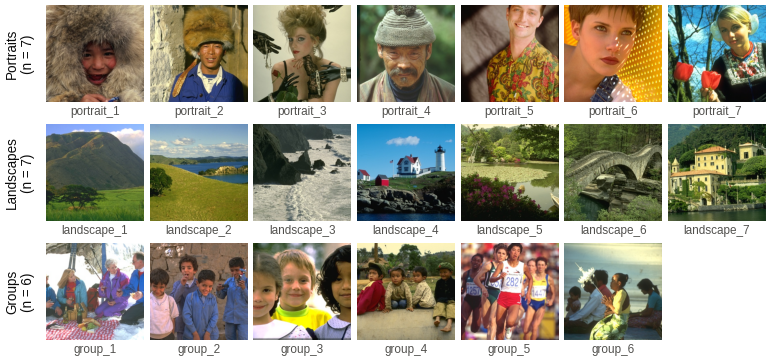

In [ ]:
def to_square(img, size=IMG_SIZE):
    h, w = img.shape[:2]
    s = min(h, w)
    y0, x0 = (h - s) // 2, (w - s) // 2
    img = img[y0:y0 + s, x0:x0 + s]
    interp = cv2.INTER_AREA if s > size else cv2.INTER_CUBIC
    return cv2.resize(img, (size, size), interpolation=interp)

def read_rgb(path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None: raise ValueError(f'Cannot read {path}')
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

import urllib.request, hashlib

BSDS_COMMIT = 'a04b7c6c3a9f0ace74bf205c72a43d32e1c72722'   # pinned version of github.com/BIDS/BSDS500
BSDS_URL = 'https://raw.githubusercontent.com/BIDS/BSDS500/' + BSDS_COMMIT + '/BSDS500/data/images/test/{}.jpg'
BSDS_PHOTOS = {   # BSDS id: (category, MD5 checksum)
    '14092': ('portrait', '9da8165fb621f46c1adf13332498a82a'),  '15062': ('portrait', '464e66695dcc3abef682075d2dd4640d'),
    '198087': ('portrait', '0a87ef1cff46ce897cf70ae9ea9e8da4'), '246009': ('portrait', '1cefa4bb78c58fc10f28ab24e9b53a92'),
    '302022': ('portrait', 'f803373b0f1ec401c83b626ff9b76580'), '388006': ('portrait', 'f685f9f211ec720c600ccb3438fcfbb8'),
    '258089': ('portrait', '02305cce4cdd3b80d012138b5ee83965'),
    '28083': ('landscape', 'e7c19bcc58de49a116bd2f3bb73be333'),  '36046': ('landscape', '1780bde47418d1dcd7c5771a897647e6'),
    '117025': ('landscape', '0fdc429100329affa18c7d2e49f6b382'), '228076': ('landscape', '4d67c261a7c3de938ac831ce3c227405'),
    '145079': ('landscape', 'cda37c9175c9f11d2fc2e493e8a1ce26'), '207049': ('landscape', '2361dd52fd00be7a5cb95b313d28cfe4'),
    '79073': ('landscape', '3b915f5e99de3bfaccd5635c9f55653e'),
    '157087': ('group', 'a456b5f14a396c50f9bf03b41770541b'), '290035': ('group', 'f6e742d799a08632849139dcae44f13d'),
    '368037': ('group', 'da6bbc4403f0480770ff3d631ec44f89'), '15011': ('group', '4f83ac60ccfbcd38f21ca969b4bba756'),
    '226043': ('group', 'bd88a6620adde00cadb84d2d30098204'), '20069': ('group', '8b2655a2e71c21fa73d0ba53c2ac292c'),
}

records, ds_rows = [], []
cat_count = {c: 0 for c in CATEGORIES}
def next_id(cat):
    # simple study ID per category: portrait_1, portrait_2, ..., landscape_1, ..., group_1, ...
    cat_count[cat] += 1
    return f'{cat}_{cat_count[cat]}'

if DATA_SOURCE == 'BSDS500':
    raw_dir = OUT / 'source_photos'; raw_dir.mkdir(exist_ok=True)
    for bid, (cat, md5) in BSDS_PHOTOS.items():
        f = raw_dir / f'{bid}.jpg'
        if not f.exists() or hashlib.md5(f.read_bytes()).hexdigest() != md5:
            urllib.request.urlretrieve(BSDS_URL.format(bid), f)
        got = hashlib.md5(f.read_bytes()).hexdigest()
        assert got == md5, f'Checksum mismatch for BSDS {bid} — file differs from the one used in the study'
        img = read_rgb(f)
        image_id = next_id(cat)
        records.append({'image_id': image_id, 'category': cat, 'img': to_square(img)})
        ds_rows.append({'image_id': image_id, 'category': cat, 'collection': 'BSDS500 (test split)', 'bsds_id': bid,
                        'original_px': f'{img.shape[1]}x{img.shape[0]}', 'md5': md5, 'url': BSDS_URL.format(bid)})
    pd.DataFrame(ds_rows).to_csv(OUT / 'tables' / 'dataset_photos.csv', index=False)
else:
    files = sorted([p for p in Path(CLEAN_DIR).iterdir() if p.suffix.lower() in ('.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp')])
    assert files, f'No images found in {CLEAN_DIR}'
    for p in files:
        cat = p.stem.split('_')[0].lower()
        assert cat in CATEGORIES, f'{p.name}: file name must start with one of {CATEGORIES}'
        image_id = next_id(cat)
        records.append({'image_id': image_id, 'category': cat, 'img': to_square(read_rgb(p))})
        ds_rows.append({'image_id': image_id, 'category': cat, 'collection': 'own folder', 'file': p.name})
    pd.DataFrame(ds_rows).to_csv(OUT / 'tables' / 'dataset_photos.csv', index=False)

for r in records:
    cv2.imwrite(str(OUT / 'clean' / f"{r['image_id']}.png"), cv2.cvtColor(r['img'], cv2.COLOR_RGB2BGR))

images = {r['image_id']: r['img'] for r in records}
cat_of = {r['image_id']: r['category'] for r in records}
print(f'{len(images)} images loaded:', pd.Series(cat_of).value_counts().to_dict())
assert len(images) == 20, f'The study uses 20 photographs, found {len(images)}.'

# Figure: the 20 photographs, one row per category (blocking factor)
ncol = max(sum(c == k for c in cat_of.values()) for k in CATEGORIES)
fig, axs = plt.subplots(3, ncol, figsize=(7.16, 3.35), gridspec_kw={'wspace': 0.04, 'hspace': 0.22})
for r, cat in enumerate(CATEGORIES):
    ids = [i for i in images if cat_of[i] == cat]
    for c in range(ncol):
        ax = axs[r, c]; image_ax(ax)
        if c < len(ids):
            ax.imshow(images[ids[c]])
            ax.set_xlabel(ids[c], fontsize=6.5, color=INK2, labelpad=2)
        else:
            ax.set_visible(False)
    axs[r, 0].set_ylabel(f'{cat.capitalize()}s\n(n = {len(ids)})', fontsize=7.5, color=INK, labelpad=6)
save_fig(fig, 'fig_dataset_20_photos'); plt.show()

## 5. Irregular damage masks (≈5 %, 20 %, 40 %)
Masks are built from uneven brush strokes (scratch/tear-like) and irregular blotches (stain-like) at random positions and sizes, added until coverage falls inside target ± 1 pp. Each image × level gets its own reproducible seed. **White (1) = damaged.**

          mean     std     min     max
level                                 
large   0.3969  0.0054  0.3914  0.4099
medium  0.1968  0.0053  0.1906  0.2093
small   0.0460  0.0045  0.0401  0.0553


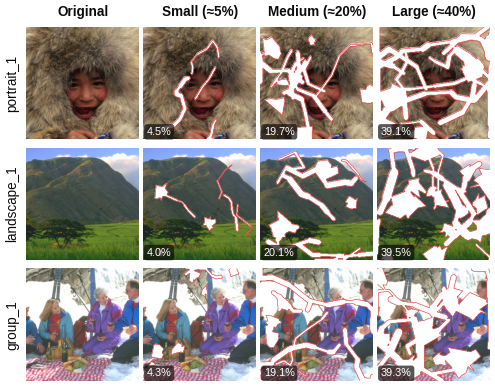

In [ ]:
def _stroke(canvas, rng, scale):
    n = rng.integers(3, 10)
    x, y = rng.integers(0, IMG_SIZE, 2)
    thick = int(max(2, rng.uniform(0.012, 0.05) * IMG_SIZE * scale))
    pts = [(int(x), int(y))]
    angle = rng.uniform(0, 2 * np.pi)
    for _ in range(n):
        angle += rng.normal(0, 0.6)                       # uneven, wandering path
        length = rng.uniform(0.04, 0.18) * IMG_SIZE * scale
        x = int(np.clip(x + length * np.cos(angle), 0, IMG_SIZE - 1))
        y = int(np.clip(y + length * np.sin(angle), 0, IMG_SIZE - 1))
        pts.append((x, y))
    for a, b in zip(pts[:-1], pts[1:]):
        t = max(1, int(thick * rng.uniform(0.6, 1.3)))    # varying width along the stroke
        cv2.line(canvas, a, b, 1, t, lineType=cv2.LINE_AA)
        cv2.circle(canvas, b, t // 2, 1, -1)

def _blotch(canvas, rng, scale):
    cx, cy = rng.integers(0, IMG_SIZE, 2)
    r = rng.uniform(0.03, 0.12) * IMG_SIZE * scale
    k = rng.integers(8, 16)
    ang = np.sort(rng.uniform(0, 2 * np.pi, k))
    rad = r * rng.uniform(0.5, 1.3, k)                    # jagged outline
    poly = np.stack([cx + rad * np.cos(ang), cy + rad * np.sin(ang)], 1).astype(np.int32)
    cv2.fillPoly(canvas, [poly], 1, lineType=cv2.LINE_AA)

def make_mask(target, seed, tol=MASK_TOL, max_tries=5000):
    rng = np.random.default_rng(seed)
    mask = np.zeros((IMG_SIZE, IMG_SIZE), np.uint8)
    scale = 0.6 + 2.0 * target                            # bigger elements for bigger targets
    for _ in range(max_tries):
        cov = mask.mean()
        if cov >= target - tol: break
        cand = mask.copy()
        (_stroke if rng.random() < 0.6 else _blotch)(cand, rng, scale)
        if cand.mean() <= target + tol:
            mask = cand
        else:
            scale = max(0.15, scale * 0.8)                # too big → try smaller pieces
    return (mask > 0).astype(np.uint8)

masks, mask_rows = {}, []
for i, img_id in enumerate(images):
    for j, (lvl, tgt) in enumerate(LEVELS.items()):
        m = make_mask(tgt, seed=SEED + 1000 * i + j)
        masks[(img_id, lvl)] = m
        cv2.imwrite(str(OUT / 'masks' / f'{img_id}__{lvl}.png'), m * 255)
        dmg = images[img_id].copy(); dmg[m.astype(bool)] = 255  # white damage, for display only
        cv2.imwrite(str(OUT / 'damaged' / f'{img_id}__{lvl}.png'), cv2.cvtColor(dmg, cv2.COLOR_RGB2BGR))
        mask_rows.append({'image_id': img_id, 'level': lvl, 'target': tgt, 'actual_coverage': m.mean()})

mask_df = pd.DataFrame(mask_rows)
mask_df.to_csv(OUT / 'tables' / 'mask_coverage.csv', index=False)
print(mask_df.groupby('level')['actual_coverage'].agg(['mean', 'std', 'min', 'max']).round(4))

# Figure for the Methods section: the three damage levels on one photograph of each category
ex_ids = [next(i for i in images if cat_of[i] == c) for c in CATEGORIES]
fig, axs = plt.subplots(len(ex_ids), 4, figsize=(4.6, 3.55), gridspec_kw={'wspace': 0.04, 'hspace': 0.06})
for r, img_id in enumerate(ex_ids):
    axs[r, 0].imshow(images[img_id])
    for c, lvl in enumerate(LEVELS, start=1):
        m = masks[(img_id, lvl)]
        show_damage(axs[r, c], images[img_id], m)
        axs[r, c].text(0.03, 0.04, f'{m.mean():.1%}', transform=axs[r, c].transAxes, fontsize=6, color='white',
                       bbox=dict(boxstyle='round,pad=0.25', fc='#0b0b0bb0', ec='none'))
    for a in axs[r]: image_ax(a)
    axs[r, 0].set_ylabel(img_id, fontsize=7.5, color=INK, labelpad=4)
for c, t in enumerate(['Original', 'Small (≈5%)', 'Medium (≈20%)', 'Large (≈40%)']):
    axs[0, c].set_title(t, fontsize=7.5, loc='center', weight='bold')
save_fig(fig, 'fig_masks'); plt.show()

## 6. The three inpainting methods
All three receive exactly the same input: the damaged RGB image (uint8, 256×256) and the binary mask. Known pixels are never changed — only the masked area is filled.

**Method 1 – PDE-based.** OpenCV `cv2.inpaint` with `INPAINT_NS` (Navier–Stokes, Bertalmío et al. 2001), OpenCV default radius = 3.

**Method 2 – Exemplar-based.** Criminisi et al. (2004) — priority = confidence × data term, best-match patch by SSD in CIELab over the whole known image, 9×9 patches (the paper's default). OpenCV has no Criminisi function, so it is implemented here with `cv2.matchTemplate` for the patch search.

**Method 3 – Diffusion-based.** ResShift (Yue et al. [17]), official pretrained ImageNet inpainting checkpoint, 4 sampling steps, default config.

In [ ]:
# ---------- Method 1: PDE (Navier–Stokes) ----------
def inpaint_pde(img, mask):
    return cv2.inpaint(img, mask * 255, 3, cv2.INPAINT_NS)

# ---------- Method 2: Exemplar (Criminisi et al., 2004) ----------
def inpaint_exemplar(img, mask, patch=9):
    h = patch // 2
    H, W = mask.shape
    pad = lambda a, v=0: cv2.copyMakeBorder(a, h, h, h, h, cv2.BORDER_CONSTANT, value=v)
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(np.float32)
    lab = cv2.copyMakeBorder(lab, h, h, h, h, cv2.BORDER_REFLECT)
    out = cv2.copyMakeBorder(img, h, h, h, h, cv2.BORDER_REFLECT).copy()
    hole = pad(mask.astype(np.uint8), 0).astype(bool)
    inside = np.zeros_like(hole); inside[h:h + H, h:h + W] = True   # real image area
    hole &= inside
    conf = (~hole).astype(np.float32)
    lab[hole] = 0
    box = np.ones((patch, patch), np.float32)
    k = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    while hole.any():
        # 1. fill front
        front = hole & cv2.dilate((~hole).astype(np.uint8), k).astype(bool)
        ys, xs = np.nonzero(front)
        # 2. confidence term
        C = cv2.filter2D(conf, -1, box, borderType=cv2.BORDER_CONSTANT) / (patch * patch)
        # 3. data term: isophote (from known pixels) · front normal
        gray = lab[..., 0] / 255.0
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3); gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        valid = cv2.erode((~hole).astype(np.uint8), k).astype(bool)
        gx[~valid] = 0; gy[~valid] = 0
        mag = gx ** 2 + gy ** 2
        nx = cv2.Sobel(hole.astype(np.float32), cv2.CV_32F, 1, 0, ksize=3)
        ny = cv2.Sobel(hole.astype(np.float32), cv2.CV_32F, 0, 1, ksize=3)
        nrm = np.sqrt(nx ** 2 + ny ** 2) + 1e-8
        # strongest known isophote inside each front pixel's patch (vectorised)
        off = np.arange(-h, h + 1)
        wy = np.clip(ys[:, None, None] + off[None, :, None], 0, mag.shape[0] - 1)
        wx = np.clip(xs[:, None, None] + off[None, None, :], 0, mag.shape[1] - 1)
        wy, wx = np.broadcast_to(wy, (len(ys), patch, patch)), np.broadcast_to(wx, (len(ys), patch, patch))
        idx = mag[wy, wx].reshape(len(ys), -1).argmax(1)
        py, px = wy.reshape(len(ys), -1)[np.arange(len(ys)), idx], wx.reshape(len(ys), -1)[np.arange(len(ys)), idx]
        D = np.abs(-gy[py, px] * nx[ys, xs] + gx[py, px] * ny[ys, xs]) / nrm[ys, xs]
        P = C[ys, xs] * (D + 1e-3)
        t = int(np.argmax(P)); y, x = ys[t], xs[t]
        # 4. best exemplar among fully-known source patches
        tgt = lab[y - h:y + h + 1, x - h:x + h + 1]
        known = (~hole[y - h:y + h + 1, x - h:x + h + 1]).astype(np.float32)
        tmask = np.repeat(known[..., None], 3, axis=2)
        ssd = cv2.matchTemplate(lab, tgt, cv2.TM_SQDIFF, mask=tmask)
        src_ok = cv2.filter2D(hole.astype(np.float32), -1, box, anchor=(0, 0),
                              borderType=cv2.BORDER_CONSTANT)[:ssd.shape[0], :ssd.shape[1]] < 0.5
        src_ok &= cv2.filter2D((~inside).astype(np.float32), -1, box, anchor=(0, 0),
                               borderType=cv2.BORDER_CONSTANT)[:ssd.shape[0], :ssd.shape[1]] < 0.5
        ssd = np.where(src_ok & np.isfinite(ssd), ssd, np.inf)
        sy, sx = np.unravel_index(np.argmin(ssd), ssd.shape)
        # 5. copy into the unknown pixels of the target patch, update confidence
        fill = ~known.astype(bool)
        sl_t = (slice(y - h, y + h + 1), slice(x - h, x + h + 1))
        sl_s = (slice(sy, sy + patch), slice(sx, sx + patch))
        out[sl_t][fill] = out[sl_s][fill]
        lab[sl_t][fill] = lab[sl_s][fill]
        conf[sl_t][fill] = C[y, x]
        hole[sl_t] = False
        hole &= inside
    return out[h:h + H, h:h + W]

# ---------- Method 3: Diffusion (ResShift, Yue et al. 2025) ----------
sys.path.insert(0, '/content/ResShift')
os.chdir('/content/ResShift')
from omegaconf import OmegaConf
from basicsr.utils.download_util import load_file_from_url

_orig_load = torch.load                          # newer PyTorch defaults to weights_only=True;
def _load(*a, **k):                              # the official checkpoints need the old behaviour
    k.setdefault('weights_only', False); return _orig_load(*a, **k)
torch.load = _load
from sampler import ResShiftSampler

t0 = time.perf_counter()
Path('weights').mkdir(exist_ok=True)
ck = load_file_from_url('https://github.com/zsyOAOA/ResShift/releases/download/v2.0/resshift_inpainting_imagenet_s4.pth',
                        model_dir='weights', progress=True, file_name='resshift_inpaint_imagenet_s4.pth')
vq = load_file_from_url('https://github.com/zsyOAOA/ResShift/releases/download/v2.0/autoencoder_vq_f4.pth',
                        model_dir='weights', progress=True, file_name='autoencoder_vq_f4.pth')
cfg = OmegaConf.load('configs/inpaint_lama256_imagenet.yaml')
cfg.model.ckpt_path = ck
cfg.autoencoder.ckpt_path = vq
cfg.diffusion.params.sf = 1
resshift = ResShiftSampler(cfg, sf=1, chop_size=IMG_SIZE * 4, chop_stride=IMG_SIZE * 4, chop_bs=1,
                           use_amp=True, seed=SEED, padding_offset=cfg.model.params.get('lq_size', 64))
model_load_time = time.perf_counter() - t0
print(f'ResShift loaded in {model_load_time:.1f}s (one-off, NOT counted in per-image time)')

@torch.no_grad()
def inpaint_diffusion(img, mask, seed=SEED):
    resshift.setup_seed(seed)
    H, W = mask.shape
    x = torch.from_numpy(img).float().div(255).permute(2, 0, 1)[None].cuda()
    m = torch.from_numpy(mask.astype(np.float32))[None, None].cuda()
    x = x * (1 - m)                                  # damaged area = 0, as in ResShift training
    # ResShift works on sizes that are multiples of 256 (our images are exactly 256x256); if another size is ever
    # used, pad image AND mask the same way (the official sampler pads only the image), then crop back.
    off = resshift.padding_offset
    ph, pw = (-H) % off, (-W) % off
    if ph or pw:
        mode = 'reflect' if (ph < H and pw < W) else 'replicate'
        xp = torch.nn.functional.pad(x, (0, pw, 0, ph), mode=mode)
        mp = torch.nn.functional.pad(m, (0, pw, 0, ph), mode=mode)
    else:
        xp, mp = x, m
    with torch.autocast('cuda'):
        y = resshift.sample_func(xp * 2 - 1, noise_repeat=False, mask=mp * 2 - 1)   # inputs in [-1, 1]; mask 1 = damaged
    y = y.float()[:, :, :H, :W] * 0.5 + 0.5
    y = y * m + x * (1 - m)                          # keep known pixels (official mask_back)
    return (y[0].permute(1, 2, 0).clamp(0, 1).cpu().numpy() * 255).round().astype(np.uint8)

METHODS = {'PDE': inpaint_pde, 'Exemplar': inpaint_exemplar, 'Diffusion': inpaint_diffusion}
os.chdir('/content')

Downloading: "https://github.com/zsyOAOA/ResShift/releases/download/v2.0/resshift_inpainting_imagenet_s4.pth" to /content/ResShift/weights/resshift_inpaint_imagenet_s4.pth



100%|██████████| 456M/456M [00:05<00:00, 83.8MB/s]


Downloading: "https://github.com/zsyOAOA/ResShift/releases/download/v2.0/autoencoder_vq_f4.pth" to /content/ResShift/weights/autoencoder_vq_f4.pth



100%|██████████| 211M/211M [00:00<00:00, 253MB/s]

Building the diffusion model with length: 4...


No module 'xformers'. Proceeding without it.


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Loading Diffusion model from /content/ResShift/weights/resshift_inpaint_imagenet_s4.pth...
Working with z of shape (1, 3, 64, 64) = 12288 dimensions.
Loading AutoEncoder model from /content/ResShift/weights/autoencoder_vq_f4.pth...
ResShift loaded in 11.9s (one-off, NOT counted in per-image time)


Quick sanity check on one image (also serves as GPU warm-up, which is excluded from timing):

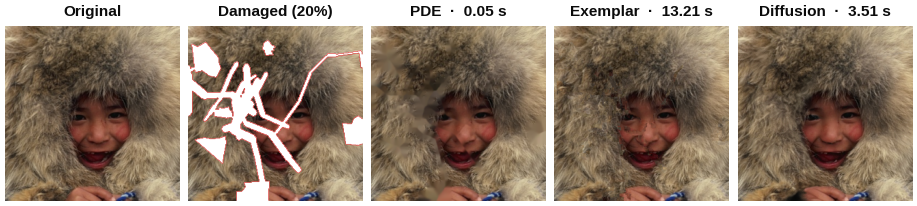

In [ ]:
img_id = list(images)[0]
fig, axs = plt.subplots(1, 5, figsize=(9, 2.2), gridspec_kw={'wspace': 0.05})
m = masks[(img_id, 'medium')]
axs[0].imshow(images[img_id]); axs[0].set_title('Original', loc='center')
show_damage(axs[1], images[img_id], m); axs[1].set_title('Damaged (20%)', loc='center')
for ax, (name, fn) in zip(axs[2:], METHODS.items()):
    t = time.perf_counter(); out = fn(images[img_id], m)
    if name == 'Diffusion': torch.cuda.synchronize()
    ax.imshow(out); ax.set_title(f'{name}  ·  {time.perf_counter() - t:.2f} s', loc='center')
for a in axs: image_ax(a)
plt.show()

## 7. Main experiment — 180 runs in randomised order
The list of (image, level, method) runs is shuffled with a fixed seed. Time is measured from input to output for each run (`perf_counter`, with `cuda.synchronize()` for the GPU method). Metrics are computed afterwards, so they are not part of the timing.

In [ ]:
runs = [(i, l, m) for i in images for l in LEVELS for m in METHODS]
random.Random(SEED).shuffle(runs)
pd.DataFrame(runs, columns=['image_id', 'level', 'method']).to_csv(OUT / 'tables' / 'run_order.csv', index_label='order')

timing = []
for k, (img_id, lvl, meth) in enumerate(runs):
    img, m = images[img_id], masks[(img_id, lvl)]
    if meth == 'Diffusion': torch.cuda.synchronize()
    t0 = time.perf_counter()
    out = METHODS[meth](img, m)
    if meth == 'Diffusion': torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    cv2.imwrite(str(OUT / 'restored' / f'{img_id}__{lvl}__{meth}.png'), cv2.cvtColor(out, cv2.COLOR_RGB2BGR))
    timing.append({'order': k, 'image_id': img_id, 'level': lvl, 'method': meth, 'time_s': dt})
    if k % 20 == 0 or k == len(runs) - 1:
        print(f'[{k + 1:3d}/{len(runs)}] {img_id:<22} {lvl:<7} {meth:<9} {dt:7.3f}s')
timing_df = pd.DataFrame(timing)
assert len(timing_df) == 180, f'Expected 180 restored outputs (20 × 3 × 3), got {len(timing_df)}'
print('Done:', len(timing_df), 'restored outputs (20 photos × 3 masks × 3 methods)')

[  1/180] landscape_5            medium  Diffusion   0.419s
[ 21/180] portrait_1             large   Exemplar   26.912s
[ 41/180] group_6                large   Diffusion   0.359s
[ 61/180] portrait_6             medium  Exemplar   13.191s
[ 81/180] landscape_1            large   Exemplar   25.299s
[101/180] landscape_6            small   Exemplar    2.989s
[121/180] group_5                small   Diffusion   0.382s
[141/180] landscape_2            small   Diffusion   0.360s
[161/180] portrait_3             small   Diffusion   0.387s
[180/180] portrait_4             medium  PDE         0.019s
Done: 180 restored outputs (20 photos × 3 masks × 3 methods)


## 8. Metrics — PSNR (Eq. 1), SSIM (Eq. 2), LPIPS (Eq. 3)
Computed between each restored image and its clean original, on the whole image (as in the paper). As an extra, PSNR is also computed **inside the damaged region only** (`PSNR_hole`) — whole-image scores are inflated when most pixels were never damaged (e.g. the 5 % level), so the hole-only value is useful for discussion.

In [ ]:
import lpips
lpips_fn = lpips.LPIPS(net='alex', verbose=False).cuda().eval()   # standard LPIPS (AlexNet, v0.1)

def to_t(a): return torch.from_numpy(a).float().div(127.5).sub(1).permute(2, 0, 1)[None].cuda()

rows = []
for r in timing:
    gt = images[r['image_id']]
    m = masks[(r['image_id'], r['level'])].astype(bool)
    out = cv2.cvtColor(cv2.imread(str(OUT / 'restored' / f"{r['image_id']}__{r['level']}__{r['method']}.png")), cv2.COLOR_BGR2RGB)
    mse_hole = np.mean((gt[m].astype(np.float64) - out[m].astype(np.float64)) ** 2)
    with torch.no_grad():
        lp = lpips_fn(to_t(gt), to_t(out)).item()
    rows.append({**r, 'category': cat_of[r['image_id']], 'coverage': m.mean(),
                 'PSNR': peak_signal_noise_ratio(gt, out, data_range=255),
                 'SSIM': structural_similarity(gt, out, channel_axis=2, data_range=255),
                 'LPIPS': lp,
                 'PSNR_hole': 10 * np.log10(255 ** 2 / max(mse_hole, 1e-10))})

df = pd.DataFrame(rows)
df['level'] = pd.Categorical(df['level'], list(LEVELS), ordered=True)
df['method'] = pd.Categorical(df['method'], list(METHODS), ordered=True)
df = df.sort_values(['image_id', 'level', 'method']).reset_index(drop=True)
df.to_csv(OUT / 'tables' / 'results_per_image.csv', index=False)
df.head(9)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 180MB/s]


,order,image_id,level,method,time_s,category,coverage,PSNR,SSIM,LPIPS,PSNR_hole
0,95,group_1,small,PDE,0.004490,group,0.042603,33.163817,0.974469,0.022003,19.458172
1,128,group_1,small,Exemplar,2.836423,group,0.042603,31.502272,0.967906,0.020175,17.796627
2,177,group_1,small,Diffusion,0.383459,group,0.042603,32.908064,0.973993,0.015193,19.202419
3,124,group_1,medium,PDE,0.017909,group,0.190567,24.680557,0.900542,0.073179,17.481035
4,36,group_1,medium,Exemplar,13.471090,group,0.190567,20.998489,0.848994,0.124492,13.798967
5,176,group_1,medium,Diffusion,0.365525,group,0.190567,25.099533,0.904102,0.047403,17.900010
6,30,group_1,large,PDE,0.036406,group,0.392883,20.099303,0.764017,0.209690,16.041939
7,52,group_1,large,Exemplar,25.108405,group,0.392883,17.207048,0.673351,0.232015,13.149684
8,86,group_1,large,Diffusion,0.363939,group,0.392883,19.561425,0.752845,0.128449,15.504061


## 9. Summary tables — mean ± SD for every method × damage level

In [ ]:
METRICS = ['PSNR', 'SSIM', 'LPIPS', 'time_s']
BETTER = {'PSNR': 'higher', 'SSIM': 'higher', 'LPIPS': 'lower', 'time_s': 'lower', 'PSNR_hole': 'higher'}

summary = df.groupby(['level', 'method'], observed=True)[METRICS + ['PSNR_hole']].agg(['mean', 'std', 'median'])
summary.to_csv(OUT / 'tables' / 'summary_method_x_level.csv')

def fmt(mean, sd, metric):
    d = {'PSNR': 2, 'PSNR_hole': 2, 'SSIM': 4, 'LPIPS': 4, 'time_s': 3}[metric]
    return f'{mean:.{d}f} ± {sd:.{d}f}'

table = pd.DataFrame({
    met: df.groupby(['level', 'method'], observed=True)[met].agg(lambda s: fmt(s.mean(), s.std(), met))
    for met in METRICS})
table.columns = ['PSNR (dB) ↑', 'SSIM ↑', 'LPIPS ↓', 'Time (s) ↓']
table.to_csv(OUT / 'tables' / 'table_main.csv')

# LaTeX version for the IEEE paper: best value per damage level in bold
lat = df.groupby(['level', 'method'], observed=True)[METRICS].agg(['mean', 'std'])
lines = [r'\begin{table}[t]', r'\centering',
         r'\caption{Restoration quality and processing time (mean $\pm$ SD, $n=%d$ images per cell).}' % df.image_id.nunique(),
         r'\label{tab:main}', r'\setlength{\tabcolsep}{3pt}', r'\begin{tabular}{llcccc}', r'\hline',
         r'Damage & Method & PSNR (dB)$\uparrow$ & SSIM$\uparrow$ & LPIPS$\downarrow$ & Time (s)$\downarrow$ \\', r'\hline']
for lvl in LEVELS:
    sub = lat.loc[lvl]
    best = {m: (sub[(m, 'mean')].idxmax() if BETTER[m] == 'higher' else sub[(m, 'mean')].idxmin()) for m in METRICS}
    for i, meth in enumerate(METHODS):
        cells = []
        for met in METRICS:
            s = fmt(sub.loc[meth, (met, 'mean')], sub.loc[meth, (met, 'std')], met).replace('±', r'$\pm$')
            cells.append(r'\textbf{' + s + '}' if best[met] == meth else s)
        label = f'{lvl.capitalize()} ({int(LEVELS[lvl]*100)}\\%)' if i == 0 else ''
        lines.append(f'{label} & {meth} & ' + ' & '.join(cells) + r' \\')
    lines.append(r'\hline')
lines += [r'\end{tabular}', r'\end{table}']
open(OUT / 'tables' / 'table_main.tex', 'w').write('\n'.join(lines))
table

PSNR (dB) ↑           SSIM ↑          LPIPS ↓  \
level  method                                                      
small  PDE        35.33 ± 3.36  0.9813 ± 0.0059  0.0157 ± 0.0081   
       Exemplar   32.34 ± 3.75  0.9709 ± 0.0065  0.0206 ± 0.0073   
       Diffusion  35.43 ± 3.21  0.9804 ± 0.0063  0.0095 ± 0.0044   
medium PDE        26.60 ± 2.84  0.9072 ± 0.0171  0.0891 ± 0.0244   
       Exemplar   23.88 ± 3.06  0.8643 ± 0.0221  0.0973 ± 0.0245   
       Diffusion  26.86 ± 2.43  0.9084 ± 0.0205  0.0430 ± 0.0108   
large  PDE        21.94 ± 2.43  0.7867 ± 0.0472  0.2156 ± 0.0640   
       Exemplar   19.70 ± 2.75  0.7070 ± 0.0418  0.2280 ± 0.0340   
       Diffusion  22.54 ± 2.75  0.7900 ± 0.0521  0.1025 ± 0.0288   

                      Time (s) ↓  
level  method                     
small  PDE         0.005 ± 0.001  
       Exemplar    3.260 ± 0.360  
       Diffusion   0.388 ± 0.016  
medium PDE         0.020 ± 0.003  
       Exemplar   13.318 ± 0.399  
       Diffusion   0.384 ± 0.021  
large  PDE         0.035 ± 0.003  
       Exemplar   25.606 ± 0.976  
       Diffusion   0.383 ± 0.020

Blocking factor — results by image content (portrait / landscape / group):

In [ ]:
by_cat = df.groupby(['category', 'level', 'method'], observed=True)[['PSNR', 'SSIM', 'LPIPS']].mean().round(4)
by_cat.to_csv(OUT / 'tables' / 'summary_by_category.csv')
by_cat.unstack('method')

PSNR                       SSIM                     \
method                PDE Exemplar Diffusion     PDE Exemplar Diffusion   
category  level                                                           
group     small   34.3242  31.0501   34.4942  0.9815   0.9708    0.9812   
          medium  25.6534  22.7385   26.0828  0.9127   0.8618    0.9177   
          large   21.1626  18.3026   21.8202  0.7912   0.6987    0.7993   
landscape small   36.4012  34.2418   36.0871  0.9793   0.9711    0.9767   
          medium  27.5812  24.7785   27.2857  0.9017   0.8642    0.8960   
          large   22.8469  20.6702   23.3676  0.7761   0.7090    0.7701   
portrait  small   35.1241  31.5368   35.5751  0.9830   0.9707    0.9834   
          medium  26.4278  23.9466   27.1034  0.9080   0.8667    0.9127   
          large   21.6870  19.9179   22.3302  0.7935   0.7120    0.8019   

                   LPIPS                     
method               PDE Exemplar Diffusion  
category  level                              
group     small   0.0145   0.0212    0.0098  
          medium  0.0720   0.1028    0.0412  
          large   0.1765   0.2389    0.0988  
landscape small   0.0212   0.0189    0.0114  
          medium  0.1109   0.0918    0.0498  
          large   0.2674   0.2170    0.1145  
portrait  small   0.0112   0.0218    0.0074  
          medium  0.0820   0.0980    0.0378  
          large   0.1972   0.2298    0.0936

## 10. Statistical comparison (exploratory)
Because every method is applied to the same image–mask pairs, the data are **paired**. With a pilot sample (n = 20 per cell) and no normality assumption, the notebook uses:
* **Friedman test** across the three methods at each damage level, and
* **Wilcoxon signed-rank** tests for each pair of methods, **Holm-corrected**, with the matched-pairs rank-biserial correlation *r* as effect size.

Treat these as exploratory, consistent with the pilot scope.

In [ ]:
def holm(p):
    p = np.asarray(p); order = np.argsort(p); adj = np.empty_like(p); run = 0
    for rank, idx in enumerate(order):
        run = max(run, (len(p) - rank) * p[idx]); adj[idx] = min(1, run)
    return adj

stat_rows = []
pairs = [('Diffusion', 'PDE'), ('Diffusion', 'Exemplar'),    # diffusion vs each classical baseline
         ('PDE', 'Exemplar')]                                 # the two baselines against each other
for met in ['PSNR', 'SSIM', 'LPIPS', 'time_s']:
    for lvl in LEVELS:
        wide = df[df.level == lvl].pivot(index='image_id', columns='method', values=met)[list(METHODS)]
        if len(wide) >= 3:
            fr = stats.friedmanchisquare(*[wide[m] for m in METHODS])
            fr_stat, fr_p = fr.statistic, fr.pvalue
        else:
            fr_stat = fr_p = np.nan
        ps, rs, meds = [], [], []
        for a, b in pairs:
            d = wide[a] - wide[b]
            try: ps.append(stats.wilcoxon(wide[a], wide[b]).pvalue)
            except ValueError: ps.append(np.nan)
            nz = d[d != 0]; rk = stats.rankdata(np.abs(nz))
            rs.append((rk[nz > 0].sum() - rk[nz < 0].sum()) / rk.sum() if len(nz) else 0.0)
            meds.append(d.median())
        adj = holm(np.nan_to_num(ps, nan=1.0))
        for (a, b), p, pa, r, md_ in zip(pairs, ps, adj, rs, meds):
            stat_rows.append({'metric': met, 'level': lvl, 'friedman_chi2': fr_stat, 'friedman_p': fr_p,
                              'comparison': f'{a} vs {b}', 'median_diff(a-b)': md_,
                              'wilcoxon_p': p, 'p_holm': pa, 'effect_r': r})
stats_df = pd.DataFrame(stat_rows).round(5)
stats_df.to_csv(OUT / 'tables' / 'statistics.csv', index=False)
stats_df

,metric,level,friedman_chi2,friedman_p,comparison,median_diff(a-b),wilcoxon_p,p_holm,effect_r
0,PSNR,small,30.1,0.0,Diffusion vs PDE,0.15560,0.72851,0.72851,0.09524
1,PSNR,small,30.1,0.0,Diffusion vs Exemplar,1.86674,0.00000,0.00001,1.00000
2,PSNR,small,30.1,0.0,PDE vs Exemplar,2.47002,0.00000,0.00001,1.00000
3,PSNR,medium,30.0,0.0,Diffusion vs PDE,0.02992,0.64766,0.64766,0.12381
4,PSNR,medium,30.0,0.0,Diffusion vs Exemplar,2.98362,0.00000,0.00001,1.00000
5,PSNR,medium,30.0,0.0,PDE vs Exemplar,2.73401,0.00000,0.00001,1.00000
6,PSNR,large,28.3,0.0,Diffusion vs PDE,0.59995,0.02958,0.02958,0.55238
7,PSNR,large,28.3,0.0,Diffusion vs Exemplar,2.57863,0.00000,0.00001,1.00000
8,PSNR,large,28.3,0.0,PDE vs Exemplar,2.14255,0.00002,0.00004,0.95238
9,SSIM,small,31.6,0.0,Diffusion vs PDE,-0.00154,0.09731,0.09731,-0.42857


### 10b. Diffusion-based method vs the two classical baselines
For every photo and mask, the diffusion result is compared with each baseline result: the mean difference (diffusion − baseline) and the share of the 20 photos where diffusion is better. For PSNR and SSIM, higher is better; for LPIPS and time, lower is better.

In [ ]:
base_rows = []
for lvl in LEVELS:
    sub = df[df.level == lvl]
    for base in ['PDE', 'Exemplar']:
        for met in ['PSNR', 'SSIM', 'LPIPS', 'time_s']:
            w = sub.pivot(index='image_id', columns='method', values=met)
            d = w['Diffusion'] - w[base]
            better = (d > 0) if BETTER[met] == 'higher' else (d < 0)
            st_ = stats_df[(stats_df.metric == met) & (stats_df.level == lvl) & (stats_df.comparison == f'Diffusion vs {base}')].iloc[0]
            base_rows.append({'level': lvl, 'baseline': base, 'metric': met,
                              'diffusion_mean': w['Diffusion'].mean(), 'baseline_mean': w[base].mean(),
                              'mean_diff (diff - base)': d.mean(), 'diffusion_better_in': f'{better.sum()}/{len(d)}',
                              'p_holm': st_.p_holm, 'effect_r': st_.effect_r})
baseline_df = pd.DataFrame(base_rows)
baseline_df.to_csv(OUT / 'tables' / 'diffusion_vs_baselines.csv', index=False)
baseline_df.round(4)

,level,baseline,metric,diffusion_mean,baseline_mean,mean_diff (diff - base),diffusion_better_in,p_holm,effect_r
0,small,PDE,PSNR,35.4300,35.3311,0.0989,11/20,0.7285,0.0952
1,small,PDE,SSIM,0.9804,0.9813,-0.0009,6/20,0.0973,-0.4286
2,small,PDE,LPIPS,0.0095,0.0157,-0.0062,20/20,0.0000,-1.0000
3,small,PDE,time_s,0.3880,0.0048,0.3832,0/20,0.0000,1.0000
4,small,Exemplar,PSNR,35.4300,32.3375,3.0925,20/20,0.0000,1.0000
5,small,Exemplar,SSIM,0.9804,0.9709,0.0095,20/20,0.0000,1.0000
6,small,Exemplar,LPIPS,0.0095,0.0206,-0.0111,20/20,0.0000,-1.0000
7,small,Exemplar,time_s,0.3880,3.2597,-2.8717,20/20,0.0000,-1.0000
8,medium,PDE,PSNR,26.8610,26.5992,0.2618,10/20,0.6477,0.1238
9,medium,PDE,SSIM,0.9084,0.9072,0.0012,11/20,0.6742,0.1143


## 11. Figures for the Results section
Simple charts, one message each:
* **`fig_psnr`, `fig_ssim`, `fig_lpips`**: one bar chart per quality measure. For each damage level there are three bars, one per method, with the mean value written on top of each bar.
* **`fig_quality_all`**: the same three charts side by side, if you prefer one figure. This version has no numbers on the bars, so it stays readable at full page width.
* **`fig_time`**: average processing time per image for each method.

Each method has the same colour in every chart: **PDE = blue, Exemplar = orange, Diffusion = green**. Every chart says whether higher or lower is better. Exact means ± SD are in Table `table_main` (Section 9). Every figure is saved as a PNG (300 dpi) and a vector PDF in `figures/`.

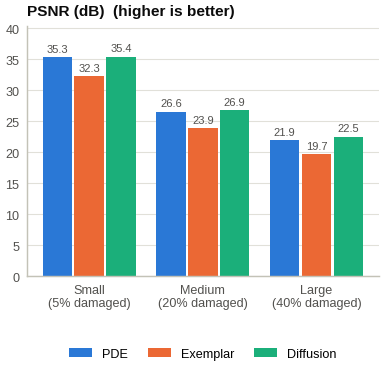

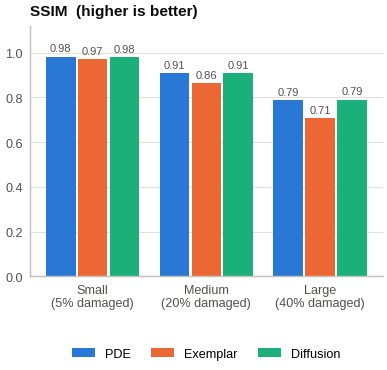

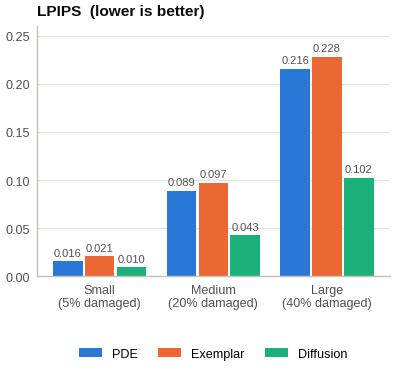

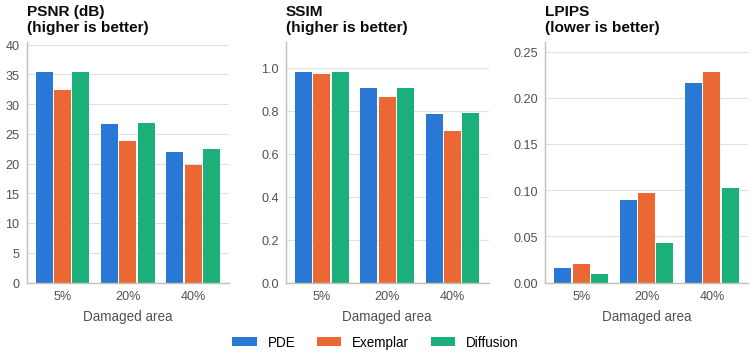

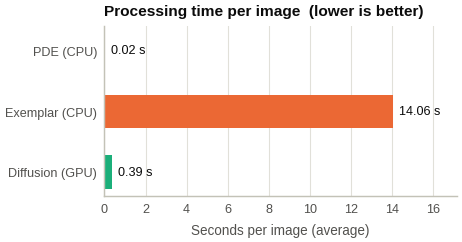

In [ ]:
lv = list(LEVELS)
LEVEL_NAME = {'small': 'Small\n(5% damaged)', 'medium': 'Medium\n(20% damaged)', 'large': 'Large\n(40% damaged)'}
QUALITY = [('PSNR', 'PSNR (dB)', 'higher is better', '{:.1f}'),
           ('SSIM', 'SSIM', 'higher is better', '{:.2f}'),
           ('LPIPS', 'LPIPS', 'lower is better', '{:.3f}')]
BAR_W = 0.26

def quality_bars(ax, met, title, better, fmt, values=True, short=False):
    # grouped bars: x = damage level, one bar per method, mean value written on top
    means = df.groupby(['level', 'method'], observed=True)[met].mean().unstack('method').reindex(lv)[METHODS_ORDER]
    top = means.values.max()
    for j, meth in enumerate(METHODS_ORDER):
        x = np.arange(len(lv)) + (j - 1) * (BAR_W + 0.02)
        ax.bar(x, means[meth].values, BAR_W, color=COL[meth], label=meth, zorder=2)
        if values:
            for xi, v in zip(x, means[meth].values):
                ax.text(xi, v + top * 0.015, fmt.format(v), ha='center', va='bottom', fontsize=6.2, color=INK2)
    if short:
        ax.set_xticks(np.arange(len(lv)), [LEVEL_LABEL[l] for l in lv]); ax.set_xlabel('Damaged area')
    else:
        ax.set_xticks(np.arange(len(lv)), [LEVEL_NAME[l] for l in lv])
    ax.set_ylim(0, top * 1.14)
    ax.grid(True, axis='y'); ax.tick_params(length=0)
    ax.set_title(f'{title}  ({better})', loc='left')

# ---------- one figure per quality measure (one IEEE column wide)
for met, title, better, fmt in QUALITY:
    fig, ax = plt.subplots(figsize=(3.5, 2.5))
    quality_bars(ax, met, title, better, fmt)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.24), ncol=3, fontsize=7)
    save_fig(fig, f'fig_{met.lower()}'); plt.show()

# ---------- the same three charts in one figure (two IEEE columns wide)
fig, axs = plt.subplots(1, 3, figsize=(7.16, 2.4), gridspec_kw={'wspace': 0.28})
for ax, (met, title, better, fmt) in zip(axs, QUALITY):
    quality_bars(ax, met, title, better, fmt, values=False, short=True)
    ax.set_title(f'{title}\n({better})', loc='left')
fig.legend(handles=[Patch(fc=COL[m], label=m) for m in METHODS_ORDER], loc='upper center',
           bbox_to_anchor=(0.5, -0.02), ncol=3, fontsize=7.5)
save_fig(fig, 'fig_quality_all'); plt.show()

# ---------- processing time: one bar per method (average over all 60 runs of that method)
t_mean = df.groupby('method', observed=True).time_s.mean().reindex(METHODS_ORDER)
fig, ax = plt.subplots(figsize=(3.5, 1.7))
y = np.arange(len(METHODS_ORDER))
ax.barh(y, t_mean.values, 0.55, color=[COL[m] for m in METHODS_ORDER], zorder=2)
for yi, v in zip(y, t_mean.values):
    ax.text(v + t_mean.max() * 0.02, yi, f'{v:.2f} s' if v >= 0.01 else f'{v:.3f} s', va='center', fontsize=7, color=INK)
ax.set_yticks(y, [f'{m} ({HW[m]})' for m in METHODS_ORDER]); ax.invert_yaxis()
ax.set_xlim(0, t_mean.max() * 1.22); ax.set_xlabel('Seconds per image (average)')
ax.grid(True, axis='x'); ax.tick_params(length=0)
ax.set_title('Processing time per image  (lower is better)', loc='left')
save_fig(fig, 'fig_time'); plt.show()

Qualitative comparison: one photograph per category, rows = damage level. The damaged areas are shown in white. Under each restoration is its **PSNR** for that image (higher = closer to the original); the best of each row is in **bold**. A second figure, `fig_qualitative_overview`, puts the three categories side by side at the largest damage level.

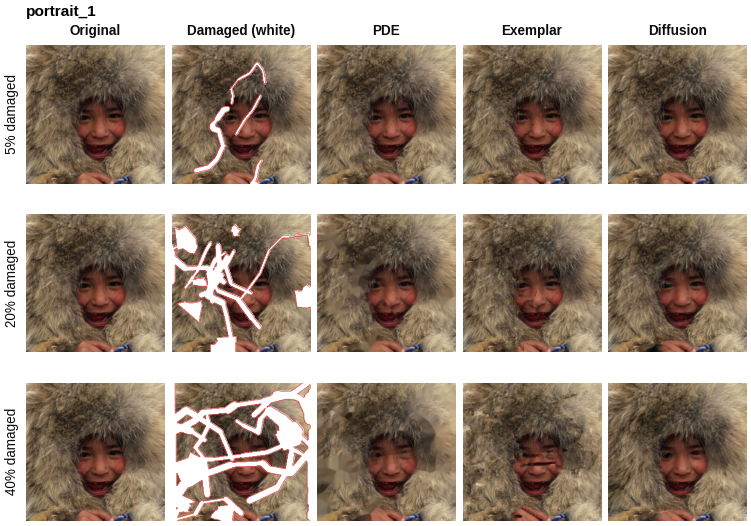

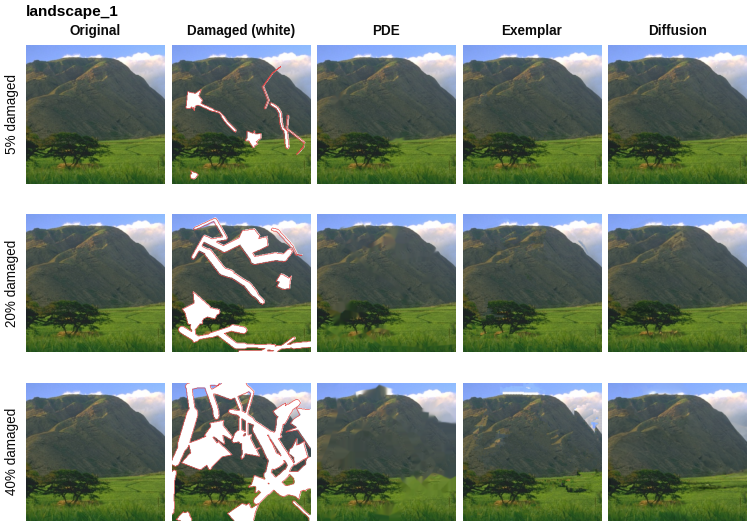

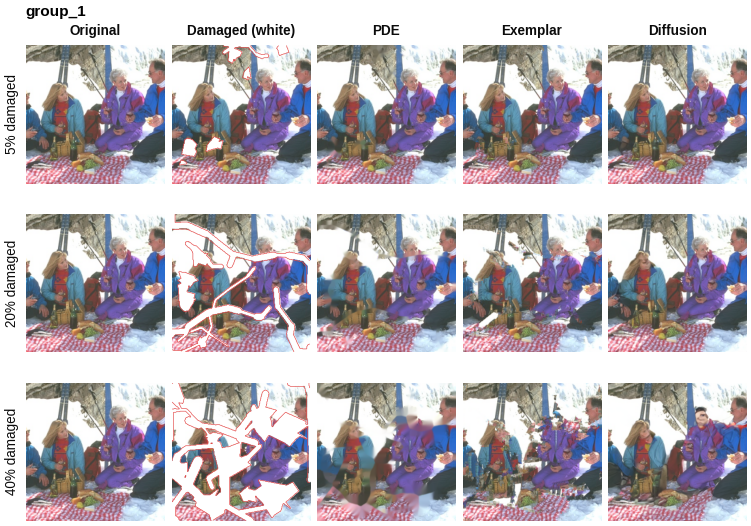

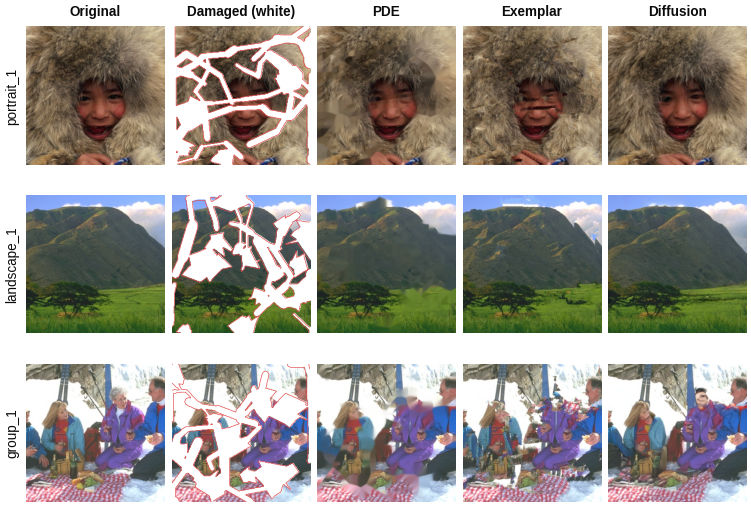

In [ ]:
def load_out(i, l, m): return cv2.cvtColor(cv2.imread(str(OUT / 'restored' / f'{i}__{l}__{m}.png')), cv2.COLOR_BGR2RGB)

def restoration_row(axs_row, img_id, lvl, first_row):
    m = masks[(img_id, lvl)]
    axs_row[0].imshow(images[img_id]); show_damage(axs_row[1], images[img_id], m)
    for c_, meth in enumerate(METHODS_ORDER, start=2):
        a_ = axs_row[c_]; a_.imshow(load_out(img_id, lvl, meth))
    for a_ in axs_row: image_ax(a_)
    if first_row:
        for a_, t in zip(axs_row, ['Original', 'Damaged (white)'] + METHODS_ORDER):
            a_.set_title(t, fontsize=7.5, loc='center', weight='bold')

examples = [next(i for i in images if cat_of[i] == c) for c in CATEGORIES]
for img_id in examples:
    fig, axs = plt.subplots(len(LEVELS), 5, figsize=(7.16, 4.75), gridspec_kw={'wspace': 0.04, 'hspace': 0.22})
    for r, lvl in enumerate(LEVELS):
        restoration_row(axs[r], img_id, lvl, r == 0)
        axs[r, 0].set_ylabel(f'{LEVEL_LABEL[lvl]} damaged', fontsize=7.5, color=INK, labelpad=4)
    fig.suptitle(img_id, x=0.125, ha='left', fontsize=8.5, weight='bold', y=0.945)
    save_fig(fig, f'fig_qualitative_{img_id}'); plt.show()

# overview: one row per category, largest damage
fig, axs = plt.subplots(len(examples), 5, figsize=(7.16, 4.75), gridspec_kw={'wspace': 0.04, 'hspace': 0.22})
for r, img_id in enumerate(examples):
    restoration_row(axs[r], img_id, 'large', r == 0)
    axs[r, 0].set_ylabel(img_id, fontsize=7.5, color=INK, labelpad=4)
save_fig(fig, 'fig_qualitative_overview'); plt.show()

## 13. Auto-generated numbers for writing the Results section
Prints the key figures in sentences, so you can copy the numbers into Section IV (always double-check against the tables).

In [ ]:
lines = []
if 'df' in globals():
    n = df.image_id.nunique()
    lines.append(f'# Key results (n = {n} photographs from BSDS500, {len(df)} restored outputs)\n')
    lines.append(f"Environment: Python {env['python']}, PyTorch {env['torch']}, OpenCV {env['opencv']}, GPU {env['gpu']} ({env['gpu_memory_GB']} GB).")
    lines.append(f'ResShift one-off model loading time: {model_load_time:.1f} s (excluded from per-image times).\n')
    cov = mask_df.groupby('level')['actual_coverage'].mean()
    lines.append('Actual mean mask coverage: ' + ', '.join(f'{l} {cov[l]*100:.1f}%' for l in LEVELS) + '.\n')
    mean = df.groupby(['level', 'method'], observed=True)[METRICS + ['PSNR_hole']].mean()
    for lvl in LEVELS:
        s = mean.loc[lvl]
        lines.append(f'## {lvl.capitalize()} damage ({int(LEVELS[lvl]*100)}%)')
        for met in ['PSNR', 'SSIM', 'LPIPS', 'PSNR_hole']:
            best = s[met].idxmax() if BETTER[met] == 'higher' else s[met].idxmin()
            lines.append(f"- {met}: best = {best} ({s.loc[best, met]:.4g}); " + ', '.join(f'{m} {s.loc[m, met]:.4g}' for m in METHODS))
        lines.append('- Time (s): ' + ', '.join(f"{m} {s.loc[m, 'time_s']:.3f}" for m in METHODS))
        sig = stats_df[(stats_df.level == lvl) & (stats_df.metric.isin(['PSNR', 'SSIM', 'LPIPS'])) & (stats_df.p_holm < 0.05)]
        for _, r in sig.iterrows():
            lines.append(f"  - {r.metric}: {r.comparison} significant (Holm p = {r.p_holm:.4f}, r = {r.effect_r:.2f})")
        lines.append('')
    lines.append('## Diffusion vs the classical baselines (mean difference, photos where diffusion is better)')
    for lvl in LEVELS:
        for base in ['PDE', 'Exemplar']:
            b = baseline_df[(baseline_df.level == lvl) & (baseline_df.baseline == base)].set_index('metric')
            lines.append(f"- {lvl} vs {base}: " + '; '.join(
                f"{m} {b.loc[m, 'mean_diff (diff - base)']:+.4g} ({b.loc[m, 'diffusion_better_in']}, Holm p = {b.loc[m, 'p_holm']:.3g})"
                for m in ['PSNR', 'SSIM', 'LPIPS', 'time_s']))
    lines.append('')
    t = df.groupby('method', observed=True)['time_s'].mean()
    lines.append('Overall mean time per image: ' + ', '.join(f'{m} {t[m]:.3f}s' for m in METHODS) +
                 f". Diffusion is {t['Diffusion']/t['PDE']:.1f}× PDE and {t['Diffusion']/t['Exemplar']:.2f}× Exemplar "
                 '(note: classical methods run on CPU, diffusion on GPU).\n')

txt = '\n'.join(lines)
open(OUT / 'results_summary.md', 'w').write(txt)
print(txt)

# Key results (n = 20 photographs from BSDS500, 180 restored outputs)

Environment: Python 3.13.16, PyTorch 2.11.0+cu130, OpenCV 5.0.0, GPU Tesla T4 (15.6 GB).
ResShift one-off model loading time: 11.9 s (excluded from per-image times).

Actual mean mask coverage: small 4.6%, medium 19.7%, large 39.7%.

## Small damage (5%)
- PSNR: best = Diffusion (35.43); PDE 35.33, Exemplar 32.34, Diffusion 35.43
- SSIM: best = PDE (0.9813); PDE 0.9813, Exemplar 0.9709, Diffusion 0.9804
- LPIPS: best = Diffusion (0.009504); PDE 0.01568, Exemplar 0.0206, Diffusion 0.009504
- PSNR_hole: best = Diffusion (22.04); PDE 21.94, Exemplar 18.94, Diffusion 22.04
- Time (s): PDE 0.005, Exemplar 3.260, Diffusion 0.388
  - PSNR: Diffusion vs Exemplar significant (Holm p = 0.0000, r = 1.00)
  - PSNR: PDE vs Exemplar significant (Holm p = 0.0000, r = 1.00)
  - SSIM: Diffusion vs Exemplar significant (Holm p = 0.0000, r = 1.00)
  - SSIM: PDE vs Exemplar significant (Holm p = 0.0000, r = 1.00)
  - LPIPS: Diffusion v

## 14. Download everything

In [ ]:
shutil.make_archive('/content/inpainting_results', 'zip', OUT)
print('Saved /content/inpainting_results.zip')
try:
    from google.colab import files; files.download('/content/inpainting_results.zip')
except Exception as e:
    print('Download manually from the Files panel:', e)

In [ ]:
# Graph of the photo-type table: PDE-based vs diffusion-based at large damage (~40%)
TYPES      = ['portrait', 'landscape', 'group']
TYPE_LABEL = {'portrait': 'Portraits', 'landscape': 'Landscapes', 'group': 'Groups'}
SHOW       = ['PDE', 'Diffusion']                       # exemplar is left out, as on slide 15
SHOW_LABEL = {'PDE': 'PDE-based', 'Diffusion': 'Diffusion-based'}
PANELS = [('PSNR',  'PSNR (dB)', 'higher is better', '{:.1f}'),
          ('SSIM',  'SSIM',      'higher is better', '{:.2f}'),
          ('LPIPS', 'LPIPS',     'lower is better',  '{:.3f}')]

large = df[df.level == 'large']
means = large.groupby(['category', 'method'], observed=True)[['PSNR', 'SSIM', 'LPIPS']].mean()
n_per_type = large.groupby('category').image_id.nunique()

fig, axs = plt.subplots(1, 3, figsize=(12, 4.2))
x, w = np.arange(len(TYPES)), 0.36
for ax, (met, title, better, fmt) in zip(axs, PANELS):
    for j, meth in enumerate(SHOW):
        vals = [means.loc[(t, meth), met] for t in TYPES]
        bars = ax.bar(x + (j - 0.5) * (w + 0.02), vals, w, color=COL[meth],
                      label=SHOW_LABEL[meth], zorder=2)
        for b in bars:
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(b.get_height()),
                    ha='center', va='bottom', fontsize=9)
    ax.set_title(title, fontsize=13, fontweight='bold', loc='left', pad=24)
    ax.text(0, 1.03, better, transform=ax.transAxes, fontsize=9.5, color='#6b7280', ha='left', va='bottom')
    ax.set_xticks(x, [f'{TYPE_LABEL[t]}\n({n_per_type[t]})' for t in TYPES])
    ax.set_ylim(0, means[met].loc[(slice(None), SHOW)].max() * 1.15)   # bars start at zero
    for s in ['top', 'right', 'left']:
        ax.spines[s].set_visible(False)
    ax.tick_params(axis='y', labelsize=9, length=0, colors='#6b7280')
    ax.tick_params(axis='x', length=0)
    ax.yaxis.grid(True, color='#e2dfd6', lw=0.8, zorder=0)
    ax.set_axisbelow(True)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0), fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.9), w_pad=3)
save_fig(fig, 'fig_by_type_large')
plt.show()

# numbers behind the graph, to check against Table III
means.loc[(TYPES, SHOW), :].unstack('method').reindex(TYPES).round(4)